# SFMS Explorer

Plots $\log_{10}(M_\star)$ vs $\log_{10}(\mathrm{sSFR})$ for every galaxy in Wang's `SAMI_CIndex_data` catalogue (`in_C == True` in the master table), with the fitted star-forming main sequence (SFMS) overlaid, and highlights one or more galaxies you pick by CATID.

**Purpose:** a quick way to find example galaxies that sit on, above, or below the SFMS for plotting/visual analysis.

**Data:** reads the most recent `outputs/csv/master_sfms_<date>.csv` + its paired `sfms_fit_params_<date>.csv` / `sfms_ridge_points_<date>.csv` (all three are written together by `src/05_sfms.py` - see `README.md` and `CHANGELOG.md` for how they're built).

**On/above/below convention:** a galaxy is classified using its `delta_ms` (vertical log(SFR) offset from the fitted ridge line) against the same `SFMS_BAND_DEX` threshold used to shade the band on the plot - `delta_ms > +band` = above, `< -band` = below, otherwise on the MS.

In [21]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Jupyter's default cwd is the notebook's own directory (sami_sf_pipeline/notebooks/).
PIPELINE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (PIPELINE_ROOT / "outputs" / "csv").exists(), (
    f"Couldn't find outputs/csv under {PIPELINE_ROOT} - "
    "run this notebook from sami_sf_pipeline/notebooks/, or adjust PIPELINE_ROOT above."
)
sys.path.insert(0, str(PIPELINE_ROOT))

from src.utils.sfms import lee2015_sfms

CSV_DIR = PIPELINE_ROOT / "outputs" / "csv"

## Load the most recent SFMS run

`05_sfms.py` writes three files together, dated by the day it was run. This finds the most recent `master_sfms_<date>.csv` and loads its two sibling files from the *same* run (not just whichever is newest individually), so the fitted line always matches the points it was actually fit to.

In [22]:
MASTER_SFMS_PATTERN = re.compile(r"^master_sfms_(\d{4}-\d{2}-\d{2})\.csv$")
candidates = sorted(
    (m.group(1), p) for p in CSV_DIR.glob("master_sfms_*.csv")
    if (m := MASTER_SFMS_PATTERN.match(p.name))
)
if not candidates:
    raise FileNotFoundError(
        f"No master_sfms_<date>.csv found in {CSV_DIR} - run src/05_sfms.py first "
        "(after 02_continuum_mask.py, 03_metrics/*.py, and 04_build_master_csv.py)."
    )
run_date, master_sfms_path = candidates[-1]

fit_params_path = CSV_DIR / f"sfms_fit_params_{run_date}.csv"
ridge_points_path = CSV_DIR / f"sfms_ridge_points_{run_date}.csv"
for p in (fit_params_path, ridge_points_path):
    if not p.exists():
        raise FileNotFoundError(f"Expected sibling file from the same 05_sfms.py run missing: {p}")

print(f"Using SFMS run dated {run_date}:")
print(f"  {master_sfms_path.name}\n  {fit_params_path.name}\n  {ridge_points_path.name}")

df = pd.read_csv(master_sfms_path)
fit_params = pd.read_csv(fit_params_path).iloc[0]
ridge_points = pd.read_csv(ridge_points_path)

S0, a1, Mt = fit_params["S0"], fit_params["a1"], fit_params["Mt"]
print(
    f"\nSFMS fit: S0={S0:.4f}  a1={a1:.4f}  Mt={Mt:.4f}  "
    f"(anchored on {fit_params['n_sf_galaxies']} galaxies, {fit_params['n_ridge_bins']} mass bins)"
)

Using SFMS run dated 2026-08-10:
  master_sfms_2026-08-10.csv
  sfms_fit_params_2026-08-10.csv
  sfms_ridge_points_2026-08-10.csv

SFMS fit: S0=2.8714  a1=0.2181  Mt=9.8895  (anchored on 1657 galaxies, 10 mass bins)


## Configuration - edit this cell, then re-run it and the plot cell below

`HIGHLIGHT_CATIDS` accepts any number of CATIDs (empty list `[]` for no highlights - just the population + SFMS).

In [25]:
#HIGHLIGHT_CATIDS = [77967, 617665, 7139]   # <-- edit these
HIGHLIGHT_CATIDS = [14812, 77967, 107528]
SFMS_BAND_DEX = 0.3                       # <-- "on the MS" half-width, in dex

## Plot

Wang's catalogue: 2959 galaxies, 2212 with valid log_Mstar/log_sSFR to plot
spectral_class
pure_SF         1201
composite_SF    1011


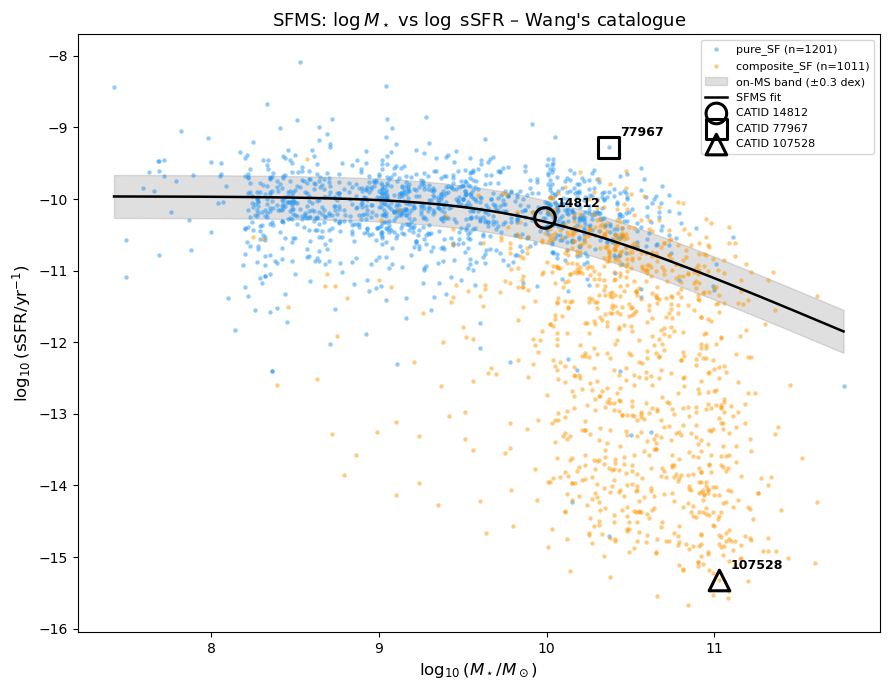

In [26]:
# Wang's catalogue = every galaxy present in concentration.csv (in_C == True).
wang = df[df["in_C"] == True].copy()
n_total = len(wang)
wang = wang.dropna(subset=["log_Mstar", "log_sSFR"])
print(f"Wang's catalogue: {n_total} galaxies, {len(wang)} with valid log_Mstar/log_sSFR to plot")
print(wang["spectral_class"].value_counts().to_string())

# SFMS line + band in log_Mstar vs log_sSFR space (sSFR_MS = SFR_MS / M*, so
# this is the fitted SFR curve minus log_Mstar, not the raw fit itself).
mstar_grid = np.linspace(wang["log_Mstar"].min(), wang["log_Mstar"].max(), 300)
sfr_ms = lee2015_sfms(mstar_grid, S0, a1, Mt)
ssfr_ms = sfr_ms - mstar_grid

fig, ax = plt.subplots(figsize=(9, 7))

CLASS_COLOURS = {"pure_SF": "#2196F3", "composite_SF": "#FF9800"}
for spec_class, colour in CLASS_COLOURS.items():
    sub = wang[wang["spectral_class"] == spec_class]
    ax.scatter(
        sub["log_Mstar"], sub["log_sSFR"], s=10, alpha=0.5, c=colour,
        linewidths=0, label=f"{spec_class} (n={len(sub)})", zorder=2,
    )

ax.fill_between(
    mstar_grid, ssfr_ms - SFMS_BAND_DEX, ssfr_ms + SFMS_BAND_DEX,
    color="grey", alpha=0.25, zorder=1, label=f"on-MS band (\u00b1{SFMS_BAND_DEX} dex)",
)
ax.plot(mstar_grid, ssfr_ms, color="black", lw=1.8, zorder=3, label="SFMS fit")

markers = ["o", "s", "^", "D", "v", "P", "X", "*"]
highlight_rows = []
for i, catid in enumerate(HIGHLIGHT_CATIDS):
    sel = df[df["CATID"] == catid]
    if sel.empty:
        print(f"  WARNING: CATID {catid} not found in the master catalogue - skipping")
        continue
    row = sel.iloc[0]
    if pd.isna(row["log_Mstar"]) or pd.isna(row["log_sSFR"]):
        print(f"  WARNING: CATID {catid} has no valid log_Mstar/log_sSFR (no Wang SFR/Mstar match) - skipping")
        continue

    dm = row["delta_ms"]
    if pd.isna(dm):
        classification = "unknown (no delta_ms)"
    elif dm > SFMS_BAND_DEX:
        classification = "above the MS"
    elif dm < -SFMS_BAND_DEX:
        classification = "below the MS"
    else:
        classification = "on the MS"

    m = markers[i % len(markers)]
    ax.scatter(
        row["log_Mstar"], row["log_sSFR"], s=220, marker=m,
        facecolors="none", edgecolors="k", linewidths=2.2, zorder=5,
        label=f"CATID {catid}",
    )
    ax.annotate(
        str(catid), (row["log_Mstar"], row["log_sSFR"]),
        textcoords="offset points", xytext=(8, 8), fontsize=9, weight="bold",
    )

    highlight_rows.append({
        "CATID": catid,
        "log_Mstar": row["log_Mstar"],
        "log_sSFR": row["log_sSFR"],
        "delta_ms": dm,
        "classification": classification,
        "spectral_class": row.get("spectral_class", np.nan),
    })

ax.set_xlabel(r"$\log_{10}(M_\star / M_\odot)$", fontsize=12)
ax.set_ylabel(r"$\log_{10}(\mathrm{sSFR} / \mathrm{yr}^{-1})$", fontsize=12)
ax.set_title("SFMS: $\\log M_\\star$ vs $\\log$ sSFR \u2013 Wang's catalogue", fontsize=13)
ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()

## Highlighted galaxy details

In [20]:
highlight_df = pd.DataFrame(highlight_rows)
highlight_df

,CATID,log_Mstar,log_sSFR,delta_ms,classification,spectral_class
0,77967,10.37,-9.278574,1.288457,above the MS,pure_SF
1,617665,9.05,-9.938490,0.082612,on the MS,pure_SF
2,7139,10.63,-12.595240,-1.819771,below the MS,composite_SF
